In [10]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

In [11]:
import sys

sys.path.append('/kaggle/input/datasets/maciejkumicki/function')
import importlib
import functions as fun
importlib.reload(fun)

import torch
from torch.utils.data import DataLoader

from functions import (
    set_seed,
    MNIST_SVHN_Dataset,
    MultiViewVAE,
    train_mvae,
    visualize_results,
)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Used device: {device}")

Used device: cuda


In [12]:
batch_size = 64

train_dataset = MNIST_SVHN_Dataset(train=True, max_samples=60000)
test_dataset = MNIST_SVHN_Dataset(train=False, max_samples=10000)

if device == torch.device("cuda"):
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
else:
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

print(f"Number of pairs in training set: {len(train_dataset)}")
print(f"Number of pairs in test set: {len(test_dataset)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 458kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.63MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.90MB/s]
100%|██████████| 182M/182M [00:02<00:00, 62.3MB/s] 
100%|██████████| 64.3M/64.3M [00:02<00:00, 30.5MB/s]


Number of pairs in training set: 56068
Number of pairs in test set: 10000


In [13]:
LATENT_DIM = 64
LR = 1e-3

model = MultiViewVAE(latent_dim=LATENT_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

In [14]:
num_epochs = 20
beta = 1.0
svhn_weight = 2.0
moe_balance_weight = 50.0

for epoch in range(1, num_epochs + 1):
    train_loss = train_mvae(
        model=model,
        dataloader=train_loader,
        optimizer=optimizer,
        epoch=epoch,
        device=device,
        beta=beta,
        svhn_weight=svhn_weight,
        moe_balance_weight=moe_balance_weight,
    )

Epoch [01] | Beta: 1.00 | Loss: 760.27 (Recon: 711.24, KL: 48.65, MoE balance: 0.008) | Joint BCE/MSE M/S: 261.22/57.25; unimodal BCE/MSE M/S: 239.81/47.86 (SVHN weighted total: 210.20) | Gate usage MNIST/SVHN: 0.493/0.507
Epoch [02] | Beta: 1.00 | Loss: 608.05 (Recon: 537.41, KL: 70.31, MoE balance: 0.007) | Joint BCE/MSE M/S: 198.69/49.95; unimodal BCE/MSE M/S: 163.07/37.87 (SVHN weighted total: 175.65) | Gate usage MNIST/SVHN: 0.538/0.462
Epoch [03] | Beta: 1.00 | Loss: 590.58 (Recon: 515.74, KL: 74.46, MoE balance: 0.007) | Joint BCE/MSE M/S: 193.51/48.40; unimodal BCE/MSE M/S: 153.50/35.96 (SVHN weighted total: 168.73) | Gate usage MNIST/SVHN: 0.540/0.460
Epoch [04] | Beta: 1.00 | Loss: 578.26 (Recon: 500.67, KL: 77.24, MoE balance: 0.007) | Joint BCE/MSE M/S: 190.37/47.17; unimodal BCE/MSE M/S: 147.68/34.13 (SVHN weighted total: 162.62) | Gate usage MNIST/SVHN: 0.539/0.461
Epoch [05] | Beta: 1.00 | Loss: 569.44 (Recon: 489.45, KL: 79.67, MoE balance: 0.006) | Joint BCE/MSE M/S: 1

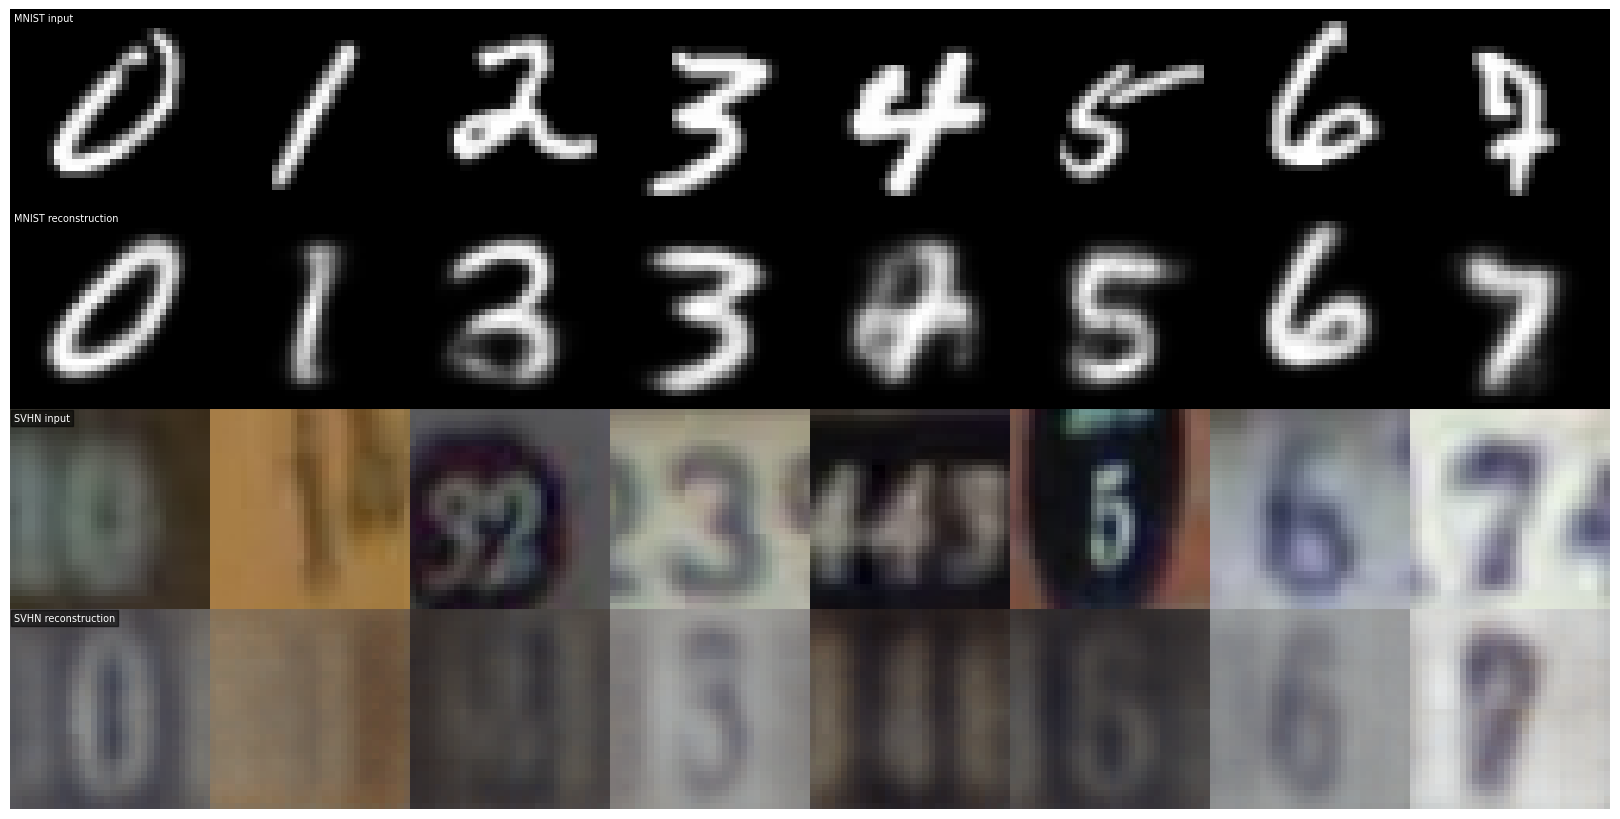

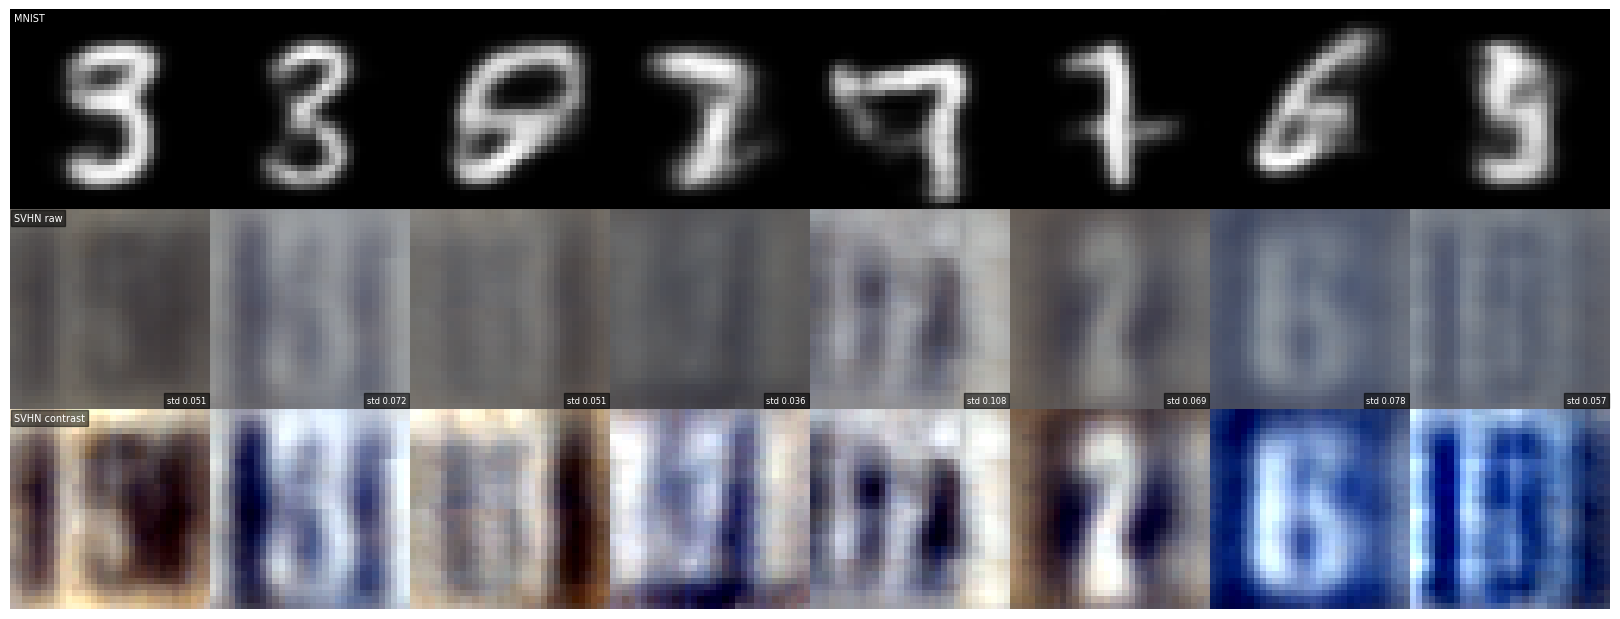

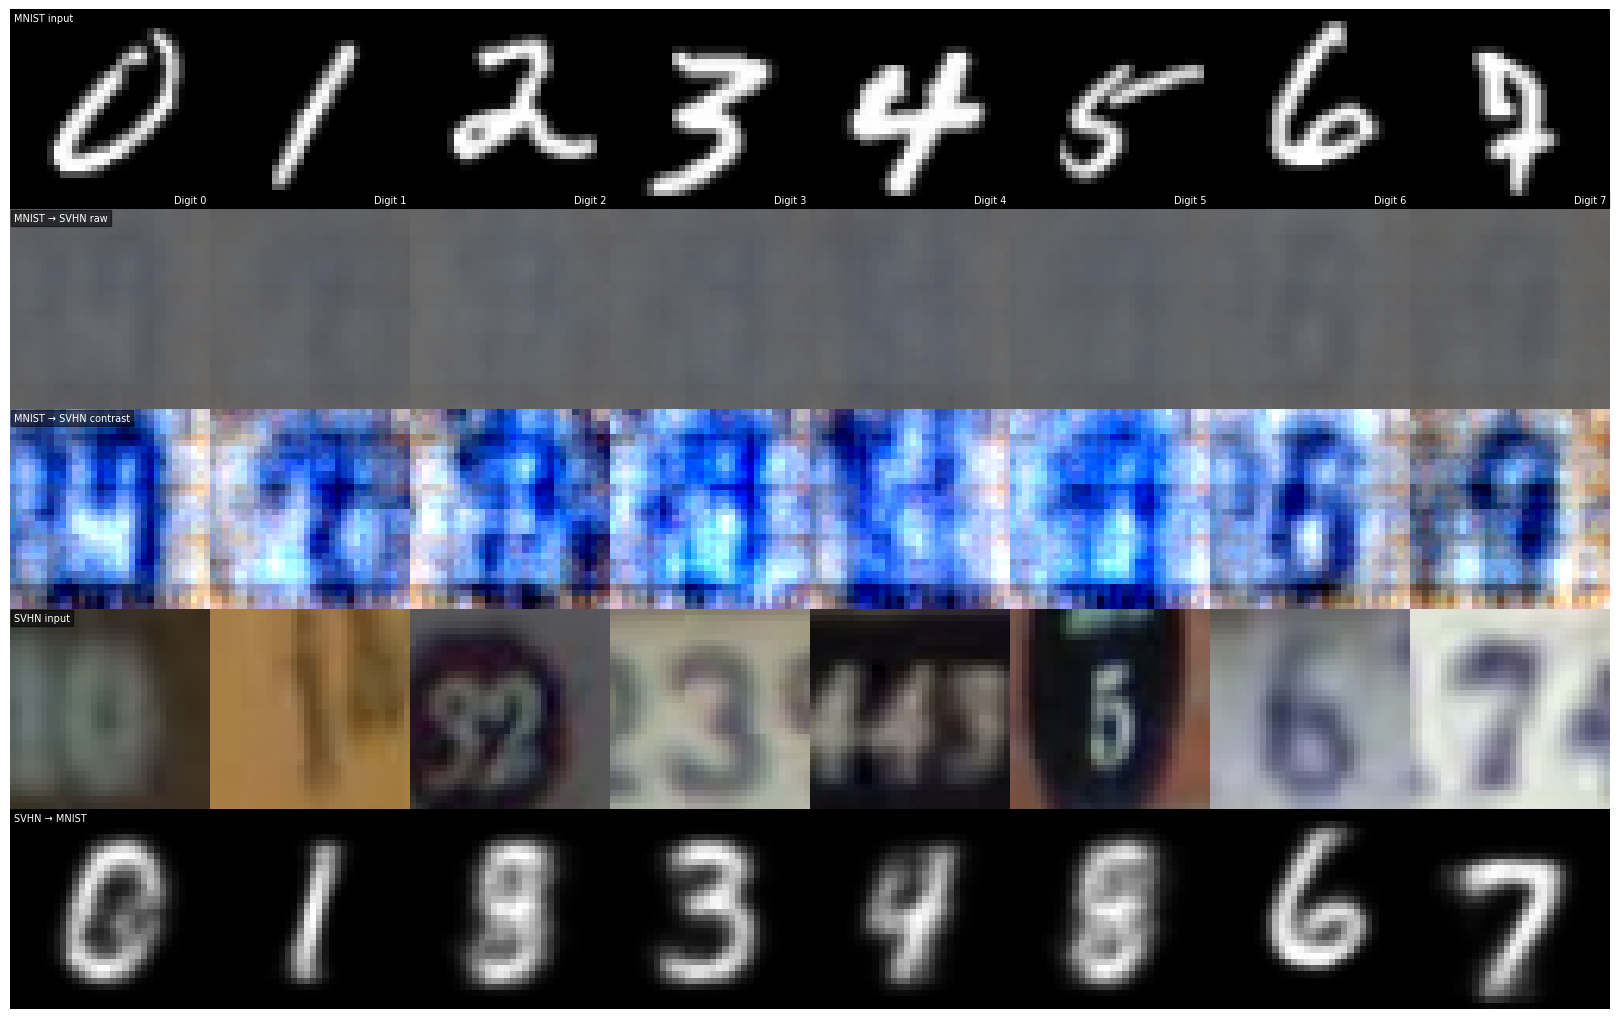

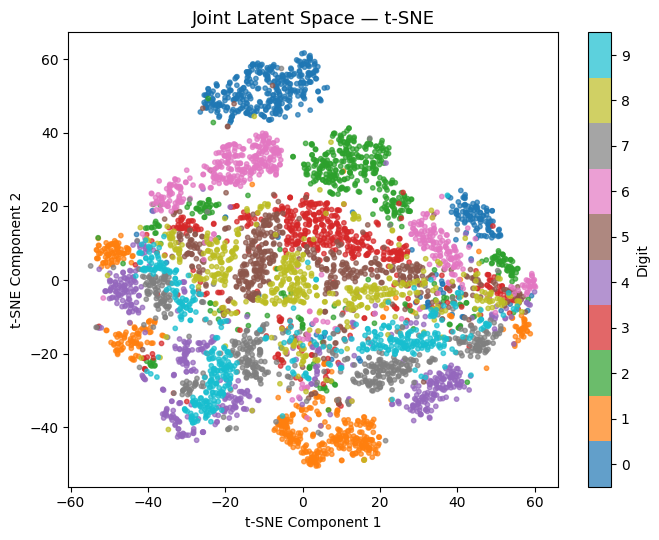

{'reconstructions': <Figure size 1600x800 with 32 Axes>,
 'prior_samples': <Figure size 1600x600 with 24 Axes>,
 'cross_domain': <Figure size 1600x1000 with 40 Axes>,
 'tsne': <Figure size 700x550 with 2 Axes>}

In [15]:
visualize_results(
    model,
    test_loader,
    device,
    tsne_samples=5000,
    save_dir="visualizations",
)

In [16]:
from datetime import datetime

MODEL_PATH = f"multi_view_vae_{datetime.now():%Y-%m-%d_%H-%M-%S}.pth"
torch.save(model.state_dict(), MODEL_PATH)
print(f"Model weights saved to: {MODEL_PATH}")


Model weights saved to: multi_view_vae_2026-10-20_14-19-33.pth
